# 07 — Restauration du checkpoint CAE
**Projet :** IndustrialDefect AI · **US-03-03 (IDL-23)** · **ST-03-03-02 (IDL-32)**

Recharge `best_model.pt` (Output de `06-cae-train`) **sur CPU et sans réentraînement**,
puis vérifie qu'il retrouve la perte de validation enregistrée dans `run_info.json`.
Le code est cloné au **commit exact** de l'entraînement.

In [1]:
import json
import shutil
import subprocess
import sys
from pathlib import Path

CATEGORY = "transistor"
INPUT = Path("/kaggle/input")

# ===== Artefacts de l'entraînement (Output de 06-cae-train, ajouté en Input) =====
run_info_files = [p for p in INPUT.rglob("run_info.json") if p.parent.name == CATEGORY]
assert len(run_info_files) == 1, f"run_info.json trouvés : {run_info_files}"
ARTIFACT_DIR = run_info_files[0].parent
RUN_INFO = json.loads(run_info_files[0].read_text("utf-8"))
CHECKPOINT = ARTIFACT_DIR / "best_model.pt"
assert CHECKPOINT.is_file(), "best_model.pt introuvable"

# ===== Code : exactement le commit utilisé pour l'entraînement =====
REPO_DIR = Path("/kaggle/temp/industrial-defect-ai")
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
subprocess.run(["git", "clone", "--quiet", RUN_INFO["code"]["repo"], str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "--quiet", RUN_INFO["code"]["git_commit"]], check=True)
sys.path.insert(0, str(REPO_DIR))

print("Artefacts      :", ARTIFACT_DIR)
print("Checkpoint     :", CHECKPOINT.name, f"({CHECKPOINT.stat().st_size / 1e6:.1f} Mo)")
print("Commit utilisé :", RUN_INFO["code"]["git_commit"])
print("Meilleure val  :", RUN_INFO["results"]["best_val_loss"], "à l'époque", RUN_INFO["results"]["best_epoch"])

Artefacts      : /kaggle/input/notebooks/zakariaelbergui/06-cae-train/cae/transistor
Checkpoint     : best_model.pt (3.4 Mo)
Commit utilisé : 6a353b3a3a3aa7a4adfa69a6db120d5bec95d73b
Meilleure val  : 0.0006124484934844077 à l'époque 98


## Restauration et vérification
Reconstruction du modèle à partir de sa configuration, chargement des poids sur CPU,
puis recalcul de la perte MSE sur le split `val` et comparaison avec `run_info.json`.

In [2]:
import torch
import torch.nn.functional as F

from src.models.convolutional_autoencoder import CAEConfig, ConvolutionalAutoencoder
from src.data.mvtec_dataset import MVTecDataset
from src.data.transforms import MVTecTransform
from src.data.dataloaders import create_dataloader

DEVICE = torch.device("cpu")

# ===== 1. Recréer le modèle avec la configuration de l'entraînement =====
cae_params = json.loads((REPO_DIR / RUN_INFO["model"]["config_file"]).read_text("utf-8"))["config"]
cae_params["image_size"] = tuple(cae_params["image_size"])
cae_params["encoder_channels"] = tuple(cae_params["encoder_channels"])
config = CAEConfig(**cae_params)
model = ConvolutionalAutoencoder(config)

# ===== 2. Charger les poids appris (aucun réentraînement) =====
state_dict = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
model.load_state_dict(state_dict)          # strict : toutes les couches doivent correspondre
model.eval()
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert n_params == RUN_INFO["model"]["trainable_parameters"], "Architecture différente !"


# ===== 3. Recalculer la perte de validation =====
def find_mvtec_root(base: Path = INPUT, category: str = "bottle") -> Path:
    candidates = [
        p.parent for p in base.rglob(category)
        if p.is_dir() and all((p / d).is_dir() for d in ("train", "test", "ground_truth"))
    ]
    assert len(candidates) == 1, f"Racines MVTec trouvées : {candidates}"
    return candidates[0]


DATASET_ROOT = find_mvtec_root()
MANIFEST = REPO_DIR / RUN_INFO["data"]["split_manifest"]
val_ds = MVTecDataset(DATASET_ROOT, MANIFEST, CATEGORY, "val",
                      MVTecTransform(size=config.image_size, profile="cae"))
assert len(val_ds) == RUN_INFO["data"]["val_images"]
val_loader = create_dataloader(val_ds, batch_size=RUN_INFO["training"]["batch_size"],
                               seed=RUN_INFO["training"]["seed"])

total_loss, n_images = 0.0, 0
with torch.inference_mode():
    for batch in val_loader:
        images = batch["image"].to(DEVICE)
        reconstructions = model(images)
        total_loss += F.mse_loss(reconstructions, images).item() * images.size(0)
        n_images += images.size(0)
restored_val_loss = total_loss / n_images

# ===== 4. Comparer avec run_info.json =====
expected_val_loss = RUN_INFO["results"]["best_val_loss"]
relative_gap = abs(restored_val_loss - expected_val_loss) / expected_val_loss

print("Paramètres chargés       :", f"{n_params:,}")
print("Images de validation     :", n_images)
print("Perte val attendue       :", f"{expected_val_loss:.10f}  (run_info.json, GPU)")
print("Perte val restaurée      :", f"{restored_val_loss:.10f}  (checkpoint rechargé, CPU)")
print("Écart relatif            :", f"{relative_gap:.2e}")
assert relative_gap < 1e-3, "La perte restaurée ne correspond pas : mauvais checkpoint ?"
print("\n✅ Checkpoint restauré sans réentraînement : il retrouve la perte de validation enregistrée.")

Paramètres chargés       : 855,619
Images de validation     : 43
Perte val attendue       : 0.0006124485  (run_info.json, GPU)
Perte val restaurée      : 0.0006124485  (checkpoint rechargé, CPU)
Écart relatif            : 3.54e-08

✅ Checkpoint restauré sans réentraînement : il retrouve la perte de validation enregistrée.


## Preuve visuelle et rapport de restauration
Images de validation, reconstructions du modèle restauré et erreur pixel par pixel ;
`restore_report.json` conserve le résultat de la vérification.

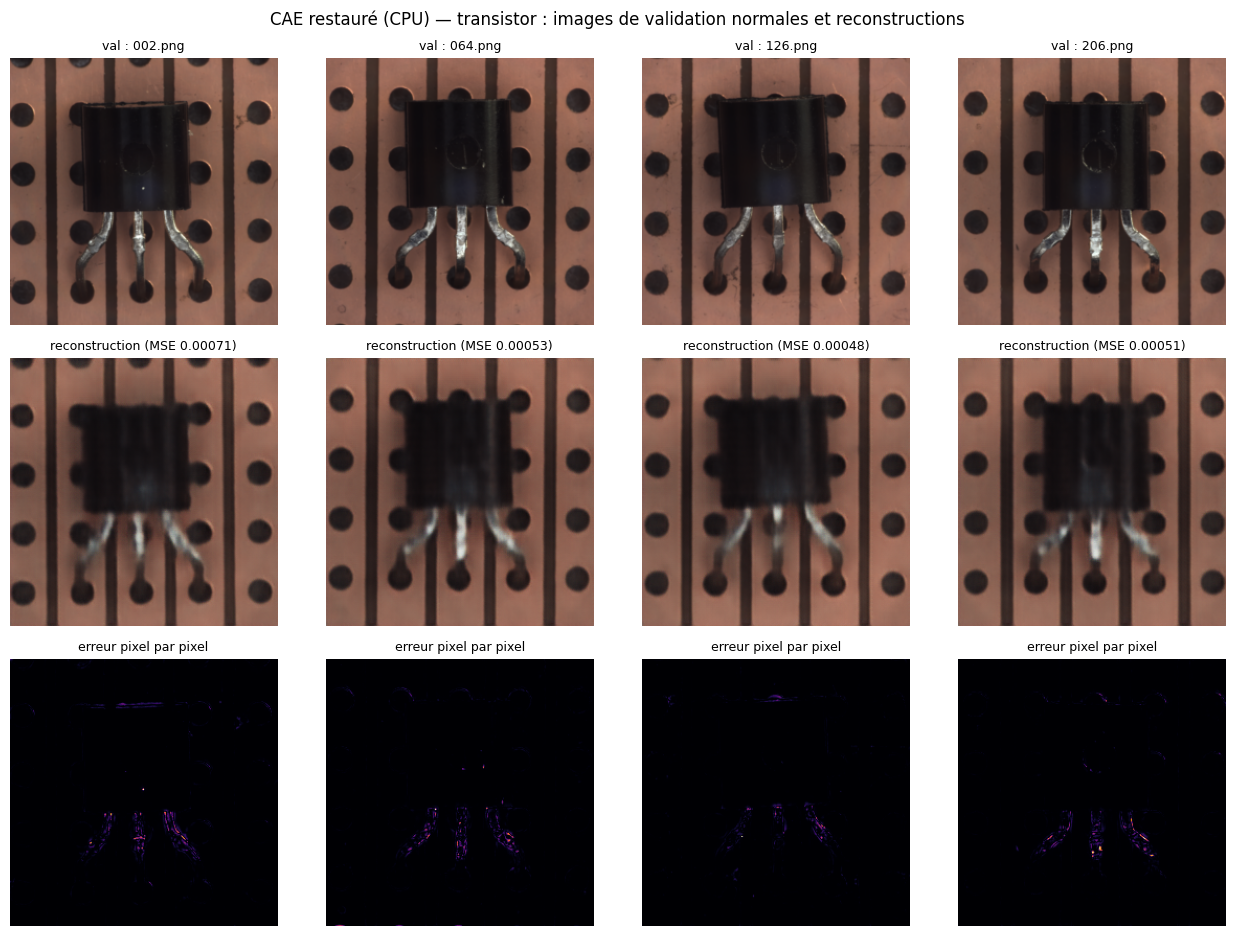

{
  "category": "transistor",
  "checked_at_utc": "2026-11-10T22:55:11+00:00",
  "checkpoint": "cae/transistor/best_model.pt",
  "git_commit": "6a353b3a3a3aa7a4adfa69a6db120d5bec95d73b",
  "device": "cpu",
  "retrained": false,
  "trainable_parameters": 855619,
  "val_images": 43,
  "expected_val_loss": 0.0006124484934844077,
  "restored_val_loss": 0.0006124485151430722,
  "relative_gap": 3.536405882959066e-08,
  "tolerance": 0.001,
  "passed": true
}


In [3]:
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = Path("/kaggle/working/restore") / CATEGORY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ===== Preuve visuelle : 4 images de validation et leur reconstruction =====
N_SHOW = 4
fig, axes = plt.subplots(3, N_SHOW, figsize=(3.2 * N_SHOW, 9.5))
with torch.inference_mode():
    for col, idx in enumerate(np.linspace(0, len(val_ds) - 1, N_SHOW, dtype=int)):
        sample = val_ds[int(idx)]
        image = sample["image"]
        recon = model(image.unsqueeze(0))[0]
        error = ((image - recon) ** 2).mean(dim=0)
        for row, (data, title) in enumerate([
            (image.permute(1, 2, 0).numpy(), f"val : {Path(sample['image_path']).name}"),
            (recon.permute(1, 2, 0).numpy(), f"reconstruction (MSE {error.mean():.5f})"),
            (error.numpy(), "erreur pixel par pixel"),
        ]):
            ax = axes[row, col]
            ax.imshow(data, cmap="inferno" if row == 2 else None)
            ax.set_title(title, fontsize=9)
            ax.axis("off")
fig.suptitle(f"CAE restauré (CPU) — {CATEGORY} : images de validation normales et reconstructions", fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "restored_reconstructions.png", dpi=110, bbox_inches="tight")
plt.show()

# ===== Rapport de restauration =====
restore_report = {
    "category": CATEGORY,
    "checked_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "checkpoint": RUN_INFO["artifacts"]["checkpoint"],
    "git_commit": RUN_INFO["code"]["git_commit"],
    "device": "cpu",
    "retrained": False,
    "trainable_parameters": n_params,
    "val_images": n_images,
    "expected_val_loss": expected_val_loss,
    "restored_val_loss": restored_val_loss,
    "relative_gap": relative_gap,
    "tolerance": 1e-3,
    "passed": bool(relative_gap < 1e-3),
}
(OUTPUT_DIR / "restore_report.json").write_text(json.dumps(restore_report, indent=2, ensure_ascii=False), "utf-8")
print(json.dumps(restore_report, indent=2, ensure_ascii=False))